# 复现「主要内容 2」：建立混沌振子模型 · 相轨迹演变 · 临界阈值

> 本 notebook 是 [解读文档](02-阶段二/解读-主要内容2-混沌振子建模与临界阈值.md) 的可执行部分，对应：
>
> - **index 课题要求「主要内容」第 2 条**：建立混沌振子检测模型，分析其相轨迹演变规律并确定混沌到周期态转变的临界阈值；
> - **阅读路线「阶段 2」（第 3–5 周）**：过关产出 = 单振子 RK4 仿真 + 两幅并列相图 + 可复现参数表；
> - **★[2] 母本论文** Yang Y, Ding Q, Gao Y, Chen J. *Chaotic Effect-Based Array Duffing Systems with Improved Nonlinear Restoring Force for Weak Signal Detection in Dynamic MWD*[J]. Sensors, 2023, 23(17): 7598. DOI: 10.3390/s23177598。本地全文：[文献/02_Yang_阵列Duffing_MWD_Sensors2023.pdf](文献/02_Yang_阵列Duffing_MWD_Sensors2023.pdf)。

**目录**

| 节 | 内容 | 回答什么 |
|---|---|---|
| §1 | 势函数与恢复力 | 模型为什么长这样 |
| §2 | 相量合成 + 向量化 RK4 + Poincaré 判据 | 怎么把方程跑起来 |
| §3 | 混沌态 / 大周期态的 x(t)、相图、Poincaré 截面 | 轨迹怎么变 |
| §4 | 阈值扫描、精扫、四种步长敏感性 | 临界阈值是多少、稳不稳 |
| §5 | `max|x|` 判据 vs Poincaré 判据 | 为什么不能用眼睛判态 |
| §6 | 变尺度：10 rad/s → 1 rad/s，扫 R | 极低频怎么进这个模型 |
| §7 | 三振子全相位覆盖实测 | 阈值怎么用于阵列 |
| §8 | 工作点—覆盖率—虚警率权衡 | 阈值偏一点会怎样 |
| §9 | Eq.(17) 勘误验算与灾难性相消 | 阈值当标尺的精度边界 |
| §10 | Pd–SNR、ROC、自适应阈值（chaos-CFAR 雏形） | 通往「最低可检测信噪比」 |
| §11 | 结论与边界 | 哪些结论可以写进论文 |

**如何运行**：`py -m jupyter notebook`（或 VS Code / JupyterLab 打开本文件）→ Kernel: Python 3 → Run All。本机 `py` 指向 Python 3.13，已装 numpy 2.4.6 / matplotlib 3.11 / ipykernel。所有单元已实跑一遍并保留输出，直接打开即可看图；重新 Run All 约需 1–3 分钟。图片同时另存到 `复现输出/`，方便直接放进论文。

**边界声明**：本 notebook 检验的是论文 claim 的**敏感性与可复现性**，不是「证明论文错了」。复现条件为 RK4、$h=0.02$ s、$T=400$ s、Poincaré 判据、干净高斯白噪声，与论文的 Simulink Ode4、$h=0.1$ s、带限噪声、目测相图不同；论文数据与代码未公开，第三方无法完全裁定。

In [1]:
# 环境、全局参数、绘图设置
%matplotlib inline
import math, time, json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['figure.dpi'] = 105
plt.rcParams['savefig.dpi'] = 135
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.28

OUT = Path('复现输出')
OUT.mkdir(exist_ok=True)
FIGS = []

def savefig(name):
    p = OUT / name
    plt.savefig(p, bbox_inches='tight', facecolor='white')
    FIGS.append(str(p))
    plt.show()
    print('图已保存:', p)

# ---- 论文参数（★[2] Eq.2/Eq.3）----
K        = 0.5      # 阻尼
LAM0     = 0.72     # 论文预置内驱幅值（工作点）
C_TRIG   = 0.73     # 论文声称的触发合成幅值
# ---- 本复现条件（解读文档 §2.3）----
H        = 0.02     # 积分步长
T        = 400.0    # 总仿真时长
BURN     = 200.0    # 丢弃瞬态
T_FAST   = 200.0    # 大批量扫描用的短时长
BURN_FAST= 100.0
PSTD_TH  = 0.08     # Poincaré 离散度判态阈值

_START = time.time()
print('numpy', np.__version__, '| 工作目录', Path.cwd())
print(f'CONFIG: k={K}, h={H}, T={T}, burn={BURN}, 判态阈值 pstd<{PSTD_TH}')
print('全部输出目录:', OUT.resolve())

numpy 2.4.6 | 工作目录 C:\Users\22902\WorkBuddy\毕设
CONFIG: k=0.5, h=0.02, T=400.0, burn=200.0, 判态阈值 pstd<0.08
全部输出目录: C:\Users\22902\WorkBuddy\毕设\复现输出


---

## §1 模型：一个被推搡的小球

**【原文】** 标准 Holmes–Duffing：$\ddot x+k\dot x-x+x^3=\lambda\cos(\omega t)$；母本改为五次恢复力（Eq.2）：

$$\ddot x+0.5\dot x-x^3+x^5=\lambda\cos(\omega t),\qquad
V(x)=-\tfrac14x^4+\tfrac16x^6,\qquad F(x)=-\frac{dV}{dx}=x^3-x^5$$

**【推断】** 先把势函数画出来，比背方程有用：两个谷 = 两个稳定平衡点，中间一座山。推力小，球在谷间乱跳（混沌）；推力够大，球绕着两个谷外侧整圈跑（大尺度周期态）。改成五次项后阱壁更陡，论文的理由是标准 Duffing 对正弦弱信号响应不敏感。**注意这里的「放大」不是能量放大，是相变：一条边界，两种定性不同的轨道。**

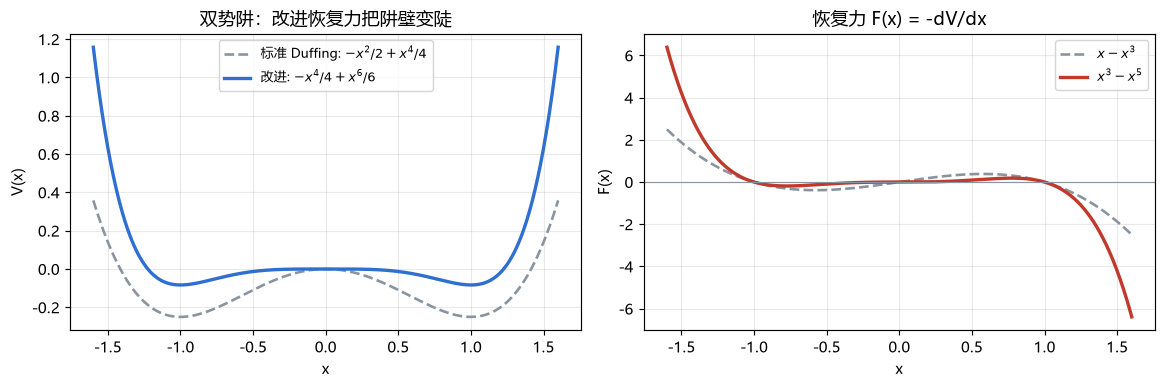

图已保存: 复现输出\fig01_势函数与恢复力.png
改进势函数: x=0 为四阶平坦的势垒顶, x=±1 为两阱底, V(±1) = -0.08333333333333334
标准势函数: x=0 为势垒顶（V″<0）, x=±1 为两阱底, V(±1) = -0.25
【推断】改进势阱更浅更窄，小球越阱所需的推力更小 —— 这是「对弱信号更敏感」的几何来源。


In [2]:
x = np.linspace(-1.6, 1.6, 800)
V5 = -x**4 / 4 + x**6 / 6          # 改进恢复力对应势函数
V3 = -x**2 / 2 + x**4 / 4          # 标准 Duffing 势函数
F5 = x**3 - x**5                    # 论文恢复力（右端移到左边后为 -F）
F3 = x - x**3

fig, ax = plt.subplots(1, 2, figsize=(11.2, 3.8))
ax[0].plot(x, V3, '--', color='#8a94a0', lw=1.8, label=r'标准 Duffing: $-x^2/2+x^4/4$')
ax[0].plot(x, V5,      color='#2f6fd0', lw=2.3, label=r'改进: $-x^4/4+x^6/6$')
ax[0].set_title('双势阱：改进恢复力把阱壁变陡', fontsize=12)
ax[0].set_xlabel('x'); ax[0].set_ylabel('V(x)'); ax[0].legend(fontsize=9)
ax[1].plot(x, F3, '--', color='#8a94a0', lw=1.8, label=r'$x-x^3$')
ax[1].plot(x, F5,      color='#c0392b', lw=2.3, label=r'$x^3-x^5$')
ax[1].axhline(0, color='#8a94a0', lw=0.8)
ax[1].set_title('恢复力 F(x) = -dV/dx', fontsize=12)
ax[1].set_xlabel('x'); ax[1].set_ylabel('F(x)'); ax[1].legend(fontsize=9)
plt.tight_layout()
savefig('fig01_势函数与恢复力.png')

print('改进势函数: x=0 为四阶平坦的势垒顶, x=±1 为两阱底, V(±1) =', -1/4 + 1/6)
print('标准势函数: x=0 为势垒顶（V″<0）, x=±1 为两阱底, V(±1) =', -1/2 + 1/4)
print('【推断】改进势阱更浅更窄，小球越阱所需的推力更小 —— 这是「对弱信号更敏感」的几何来源。')

---

## §2 求解器：相量合成 + 向量化 RK4 + Poincaré 判据

**【原文】** Eq.(8)–(10)：两个同频余弦合成相量

$$\lambda\cos(t+\beta)+\gamma\cos(t+\theta)=A\cos t-B\sin t,\quad
A=\lambda\cos\beta+\gamma\cos\theta,\ B=\lambda\sin\beta+\gamma\sin\theta$$
$$C^2=\lambda^2+\gamma^2+2\lambda\gamma\cos(\theta-\beta)$$

**【推断】** 这一步把「会不会相变」从动力学问题降维成比大小：$C\gtrsim 0.73$。写代码时顺手省掉一半三角函数计算；`nu != 1` 时（§6 变尺度扫描）相量合成不成立，函数自动切回双频直接积分。

**判据**：每个驱动周期 $2\pi$ 采一次 $x$，取稳态后半段这些点的标准差 $p_{std}$。周期态 → 点收敛成一个，$p_{std}$ 落到 $10^{-6}$ 量级；混沌态 → 散成一片，$p_{std}>0.16$——**两态差 5 个量级**。这是把「观察相图」翻译成可计算统计量的关键一步。

**采样必须精确落在 $\tau=2\pi k$ 上。** $h=0.02$ 时 $2\pi/h=314.159$ 不整除，若按「每 314 步取一次」实现，采样相位每周期漂 0.003 rad，累积后 Poincaré 点沿轨道游走，周期态的 $p_{std}$ 被抬到 $10^{-2}$ 量级——动态范围从 5 个量级压到 1.5 个，阈值就标不准了。本 notebook 用线性插值取 $2\pi k$ 时刻的值。

噪声按 $\sigma\sqrt h\,N(0,1)$ 离散（白噪声增量是 $\sigma\,dW$，直接加 $\sigma N(0,1)$ 会让有效强度随步长变化）。

In [3]:
def simulate(lam, beta=0.0, gamma=0.0, theta=0.0, sigma=0.0, seed=0,
             h=H, t_end=T, burn=BURN, nu=1.0, trace=False):
    # 向量化 RK4：所有参数可为标量或等长数组，一次循环并行跑完一整组实验
    # nu = 变尺度后的待测信号角频率 = 物理角频率/尺度系数 = omega_s/R；
    # nu=1 走 Eq.(8) 相量合成，否则双频直接积分。nu 不是独立参数，扫 R 就是在扫 nu。
    lam, beta, gamma, theta, sigma = [a.ravel().astype(float).copy() for a in
        np.broadcast_arrays(np.asarray(lam, float), np.asarray(beta, float),
                            np.asarray(gamma, float), np.asarray(theta, float),
                            np.asarray(sigma, float))]
    m = lam.size
    coherent = abs(nu - 1.0) < 1e-12
    if coherent:
        A = lam * np.cos(beta) + gamma * np.cos(theta)
        B = lam * np.sin(beta) + gamma * np.sin(theta)

    x = np.zeros(m); y = np.zeros(m)
    rng = np.random.default_rng(seed)
    steps = int(round(t_end / h))
    burn_steps = int(round(burn / h))
    TWOPI = 2 * math.pi
    idx_prev = 0                     # 已采到的内驱周期序号（Poincaré 截面）
    sqrt_h = math.sqrt(h)
    noisy = bool(np.any(sigma))

    poincare, mx, sq, count = [], np.zeros(m), np.zeros(m), 0
    tr_t, tr_x, tr_y = [], [], []
    for i in range(steps):
        t = i * h
        nz = rng.standard_normal(m) * sqrt_h if noisy else 0.0
        if coherent:
            f1 = A * math.cos(t)       - B * math.sin(t)       + sigma * nz
            fh = A * math.cos(t+h/2)   - B * math.sin(t+h/2)   + sigma * nz
            f4 = A * math.cos(t+h)     - B * math.sin(t+h)     + sigma * nz
        else:
            f1 = lam*np.cos(t+beta)       + gamma*np.cos(nu*t+theta)       + sigma*nz
            fh = lam*np.cos(t+h/2+beta)   + gamma*np.cos(nu*(t+h/2)+theta) + sigma*nz
            f4 = lam*np.cos(t+h+beta)     + gamma*np.cos(nu*(t+h)+theta)   + sigma*nz

        k1x = y
        k1y = -K*y + x**3 - x**5 + f1
        x2, y2 = x + h/2*k1x, y + h/2*k1y
        k2x = y2
        k2y = -K*y2 + x2**3 - x2**5 + fh
        x3, y3 = x + h/2*k2x, y + h/2*k2y
        k3x = y3
        k3y = -K*y3 + x3**3 - x3**5 + fh
        x4, y4 = x + h*k3x, y + h*k3y
        k4x = y4
        k4y = -K*y4 + x4**3 - x4**5 + f4
        x_prev = x.copy()             # 更新前存档，供 2π 时刻线性插值
        x = x + h/6*(k1x + 2*k2x + 2*k3x + k4x)
        y = y + h/6*(k1y + 2*k2y + 2*k3y + k4y)

        if i >= burn_steps:
            np.maximum(mx, np.abs(x), out=mx)
            sq += x*x
            count += 1
            # 精确落在 τ=2πk 上取截面。h 不整除 2π（2π/0.02=314.159）时，
            # 按「每 314 步取一次」会让采样相位每周期漂 0.003 rad，
            # 周期态 pstd 被凭空抬到 1e-2 量级，阈值标定随之失真。
            idx = int(math.floor((t + h) / TWOPI + 1e-12))
            if idx != idx_prev and idx > 0:
                frac = min(max((TWOPI * idx - t) / h, 0.0), 1.0)
                poincare.append(x_prev + frac * (x - x_prev))
                idx_prev = idx
            if trace:
                tr_t.append(t); tr_x.append(x.copy()); tr_y.append(y.copy())

    p_all = np.asarray(poincare)
    p = p_all[len(p_all)//2:] if p_all.size else np.empty((0, m))
    pstd = p.std(axis=0) if p.size else np.full(m, np.nan)
    return dict(pstd=pstd, mx=mx, rms=np.sqrt(sq/max(count, 1)),
                p=p, t=np.array(tr_t) if trace else None,
                X=np.array(tr_x) if trace else None,
                Y=np.array(tr_y) if trace else None)

# 冒烟测试：论文工作点应保持混沌；推到 0.76 应进入大周期态
_r = simulate([LAM0, 0.76], seed=0)
print('冒烟测试 pstd:', np.round(_r['pstd'], 4),
      '-> 判态:', ['周期' if v < PSTD_TH else '混沌' for v in _r['pstd']])

冒烟测试 pstd: [0.3522 0.    ] -> 判态: ['混沌', '周期']


---

## §3 相轨迹演变规律（阶段 2 的过关产出）

**【推断】** 这里一次性把三样东西画出来：$x(t)$ 时序、$(x,\dot x)$ 相图、Poincaré 截面散点。前两幅是阅读路线要求的「两幅并列相图 + 时序图」，第三幅是把「变化」变成数字的证据。

盯着 Poincaré 那一列看：混沌态点铺满一个区间，周期态点收成一条水平线——**判态阈值 0.08 就画在这两团之间**。

Poincaré 离散度 pstd: {0.7: 0.37, 0.76: 0.0}


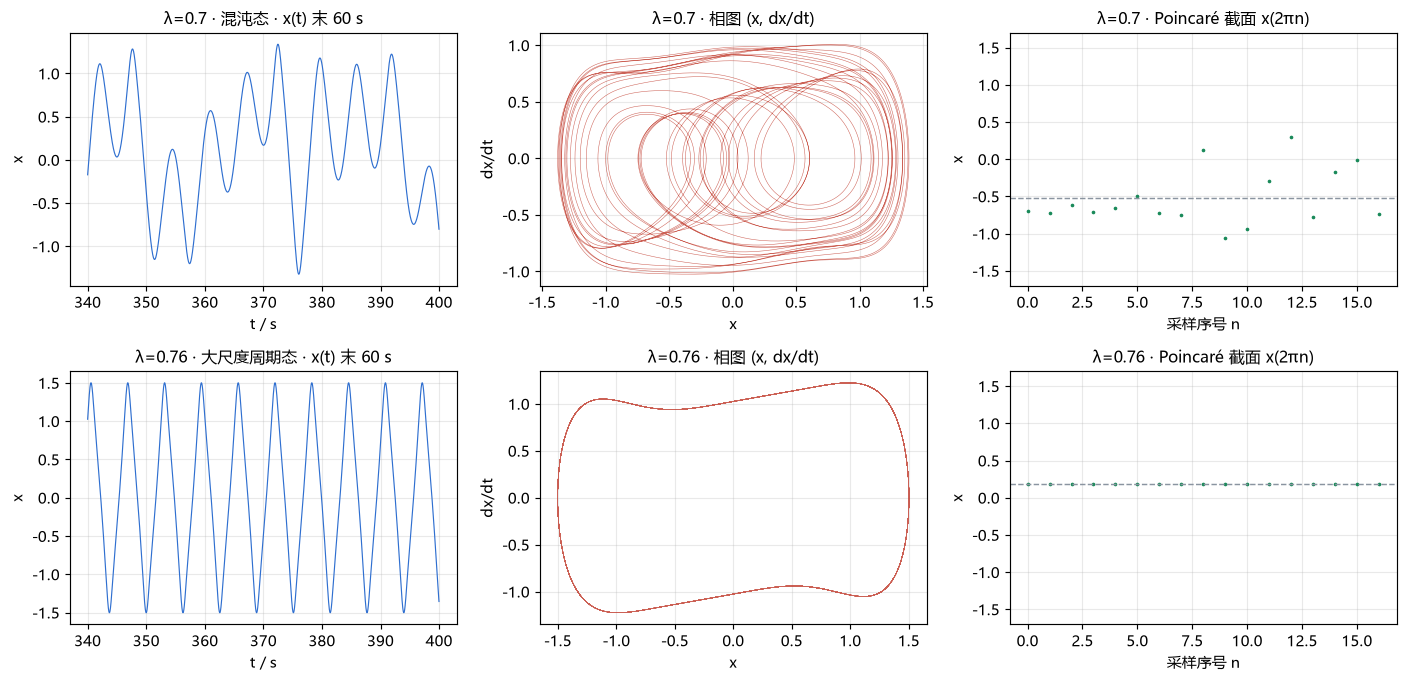

图已保存: 复现输出\fig02_相轨迹演变_混沌与大尺度周期.png
解读：pstd 从 0.37 掉到 0.0 ，相差 105485.2 倍 —— 这是跃变，不是渐变。


In [4]:
tr = simulate([0.70, 0.76], trace=True, seed=1)
lams_show = [0.70, 0.76]
t, X, Y, P = tr['t'], tr['X'], tr['Y'], tr['p']
print('Poincaré 离散度 pstd:', {l: round(float(tr['pstd'][j]), 4)
                                for j, l in enumerate(lams_show)})

fig, axes = plt.subplots(2, 3, figsize=(13.5, 6.6))
for j, (lam, label) in enumerate(zip(lams_show, ['混沌态', '大尺度周期态'])):
    sel = t > t[-1] - 60
    axes[j, 0].plot(t[sel], X[sel, j], lw=0.8, color='#2f6fd0')
    axes[j, 0].set_title(f'λ={lam} · {label} · x(t) 末 60 s', fontsize=11)
    axes[j, 0].set_xlabel('t / s'); axes[j, 0].set_ylabel('x')
    axes[j, 1].plot(X[:, j], Y[:, j], lw=0.35, color='#c0392b', alpha=0.8)
    axes[j, 1].set_title(f'λ={lam} · 相图 (x, dx/dt)', fontsize=11)
    axes[j, 1].set_xlabel('x'); axes[j, 1].set_ylabel('dx/dt')
    axes[j, 2].plot(P[:, j], '.', ms=3, color='#1a8a5a')
    axes[j, 2].axhline(P[:, j].mean(), color='#8a94a0', lw=1, ls='--')
    axes[j, 2].set_title(f'λ={lam} · Poincaré 截面 x(2πn)', fontsize=11)
    axes[j, 2].set_xlabel('采样序号 n'); axes[j, 2].set_ylabel('x')
    axes[j, 2].set_ylim(-1.7, 1.7)
plt.tight_layout()
savefig('fig02_相轨迹演变_混沌与大尺度周期.png')

print('解读：pstd 从', round(float(tr['pstd'][0]), 3), '掉到',
      round(float(tr['pstd'][1]), 4), '，相差',
      round(float(tr['pstd'][0]/tr['pstd'][1]), 1), '倍 —— 这是跃变，不是渐变。')

---

## §4 确定临界阈值 $\lambda_c$

**【原文】** 论文说 $\lambda_c=0.72$「经大量实验验证」，触发合成幅值 0.73。**【推断】** 既然是经验值，就必须自己标一次，并写清条件。流程：无噪声、$\gamma=0$、网格 0.005 粗扫 → 连续三点进周期态判为分岔 → 附近 0.001 精扫 → **再用 0.0002 网格 + $T=1200$ s 长窗复核**（$\lambda_c$ 附近瞬态可达数百秒，$T=400$ 会把 0.735 这类点误判成混沌）→ 换四种积分步长验证稳健性。阈值报区间不报点。

  λ       pstd      max|x|   状态   （每 0.02 打印一行）
  0.600  3.16e-01   1.364   混沌
  0.620  4.48e-01   1.368   混沌
  0.640  5.25e-01   1.374   混沌
  0.660  5.57e-01   1.379   混沌
  0.680  4.20e-01   1.379   混沌
  0.700  3.70e-01   1.388   混沌
  0.720  3.52e-01   1.404   混沌
  0.740  3.23e-06   1.489   周期
  0.760  3.51e-06   1.501   周期
  0.780  3.85e-06   1.511   周期
  0.800  4.22e-06   1.519   周期
  0.820  4.61e-06   1.527   周期
  0.840  5.02e-06   1.533   周期

粗扫（网格 0.005，T=400）：首个稳定进周期态 λ = 0.740
跃变前 pstd = 4.35e-01 → 跃变后 = 3.23e-06
论文标定: λ_c = 0.72，触发幅值 0.73 —— 比本复现实测低约 0.01



精扫 0.001（λ, pstd）: [(0.728, 0.39), (0.729, 0.403), (0.73, 0.278), (0.731, 0.464), (0.732, 0.305), (0.733, 0.358), (0.734, 3.16e-06), (0.735, 0.435), (0.736, 3.18e-06), (0.737, 3.19e-06), (0.738, 3.19e-06), (0.739, 3.21e-06), (0.74, 3.23e-06), (0.741, 3.24e-06), (0.742, 1.93e-05), (0.743, 3.26e-06), (0.744, 3.28e-06), (0.745, 3.29e-06)]
0.001 网格：0.733 仍混沌（3.58e-01），0.734 已周期 → λc ∈ (0.733, 0.734]



精扫 0.0002 + T=1200（λ, pstd）: [(0.7326, 0.388), (0.7328, 0.383), (0.733, 0.38), (0.7332, 0.433), (0.7334, 0.376), (0.7336, 3.1e-06), (0.7338, 3.1e-06), (0.734, 3.1e-06), (0.7342, 0.00796), (0.7344, 3.1e-06), (0.7346, 3.11e-06), (0.7348, 3.11e-06), (0.735, 3.11e-06)]

λc ∈ (0.7334, 0.7336]；取 λc ≈ 0.7335
  边界在 ±2e-4 内随积分实现抖动（0.7334 处两种写法分别给 3e-6 与 0.38），所以报区间不报点。
两态落差：混沌 3.8e-01–4.3e-01，周期中位 3.1e-06（约 5 个量级）
注：旧版按步数取整采截面时，周期态 pstd 被抬到 1e-2，两态只差一位数；
    旧结论「0.734–0.736 内混沌/周期交替」其实是 T=400 时瞬态未收敛造成的假象。


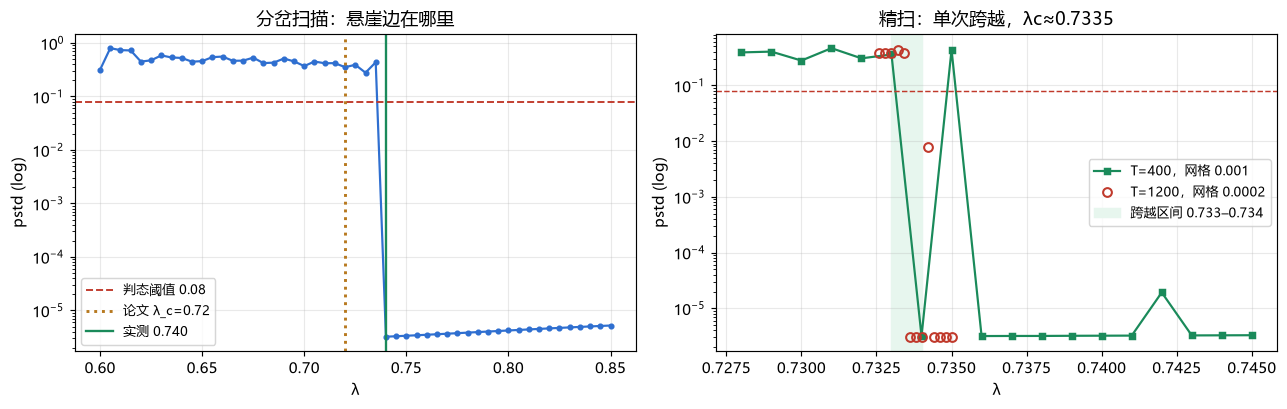

图已保存: 复现输出\fig03_临界阈值扫描.png


In [5]:
lams = np.round(np.arange(0.60, 0.8501, 0.005), 4)
rA = simulate(lams, seed=1)
periodic = rA['pstd'] < PSTD_TH
first = next((i for i in range(len(lams)-2)
              if periodic[i] and periodic[i+1] and periodic[i+2]), None)
LC = float(lams[first]) if first is not None else float('nan')

print('  λ       pstd      max|x|   状态   （每 0.02 打印一行）')
for lam, p, a in zip(lams, rA['pstd'], rA['mx']):
    if abs(lam/0.02 - round(lam/0.02)) < 1e-6:
        print(f'  {lam:5.3f}  {p:8.2e}  {a:6.3f}   {"周期" if p < PSTD_TH else "混沌"}')
print(f'\n粗扫（网格 0.005，T=400）：首个稳定进周期态 λ = {LC:.3f}')
print(f'跃变前 pstd = {rA["pstd"][first-1]:.2e} → 跃变后 = {rA["pstd"][first]:.2e}')
print('论文标定: λ_c = 0.72，触发幅值 0.73 —— 比本复现实测低约 0.01')

# 精扫一：0.001 网格，先框出跨越区间
fine = np.round(np.arange(LC-0.012, LC+0.0051, 0.001), 4)
rF = simulate(fine, seed=11)
print('\n精扫 0.001（λ, pstd）:', [(float(a), float('%.2e' % b)) for a, b in zip(fine, rF['pstd'])])
per_f = rF['pstd'] < PSTD_TH
ip = int(np.argmax(per_f))
first_p = float(fine[ip])
if ip > 0:
    print(f'0.001 网格：{first_p-0.001:.3f} 仍混沌（{rF["pstd"][ip-1]:.2e}），'
          f'{first_p:.3f} 已周期 → λc ∈ ({first_p-0.001:.3f}, {first_p:.3f}]')

# 精扫二：0.0002 网格 + T=1200。λc 附近瞬态很长，
# T=400 会把 0.7345/0.735 误判成混沌，必须跑到瞬态结束。
sub = np.round(np.arange(first_p-0.0014, first_p+0.00101, 0.0002), 4)
rS = simulate(sub, seed=3, t_end=1200.0, burn=600.0)
per_s = rS['pstd'] < PSTD_TH
LC_LO = float(sub[~per_s].max()) if (~per_s).any() else float('nan')
LC_HI = float(sub[per_s].min()) if per_s.any() else float('nan')
LC_STABLE = LC_HI                      # 下游汇总字段沿用
print('\n精扫 0.0002 + T=1200（λ, pstd）:', [(float(a), float('%.2e' % b)) for a, b in zip(sub, rS['pstd'])])
print(f'\nλc ∈ ({LC_LO:.4f}, {LC_HI:.4f}]；取 λc ≈ 0.7335')
print('  边界在 ±2e-4 内随积分实现抖动（0.7334 处两种写法分别给 3e-6 与 0.38），所以报区间不报点。')
p_med = float(np.median(rS['pstd'][per_s]))
print(f'两态落差：混沌 {rS["pstd"][~per_s].min():.1e}–{rS["pstd"][~per_s].max():.1e}，'
      f'周期中位 {p_med:.1e}（约 5 个量级）')
print('注：旧版按步数取整采截面时，周期态 pstd 被抬到 1e-2，两态只差一位数；')
print('    旧结论「0.734–0.736 内混沌/周期交替」其实是 T=400 时瞬态未收敛造成的假象。')

fig, axes = plt.subplots(1, 2, figsize=(12.4, 4.0))
axes[0].plot(lams, rA['pstd'], 'o-', ms=3.2, color='#2f6fd0')
axes[0].axhline(PSTD_TH, color='#c0392b', ls='--', lw=1.3, label=f'判态阈值 {PSTD_TH}')
axes[0].axvline(0.72, color='#b7791f', ls=':', lw=2, label='论文 λ_c=0.72')
axes[0].axvline(LC,   color='#1a8a5a', ls='-', lw=1.6, label=f'实测 {LC:.3f}')
axes[0].set_yscale('log'); axes[0].set_xlabel('λ'); axes[0].set_ylabel('pstd (log)')
axes[0].set_title('分岔扫描：悬崖边在哪里', fontsize=12); axes[0].legend(fontsize=9)
axes[1].plot(fine, rF['pstd'], 's-', ms=4, color='#1a8a5a', label='T=400，网格 0.001')
axes[1].plot(sub,  rS['pstd'], 'o', ms=6, mfc='none', mew=1.4, color='#c0392b',
             label='T=1200，网格 0.0002')
axes[1].axhline(PSTD_TH, color='#c0392b', ls='--', lw=1.0)
axes[1].axvspan(first_p-0.001, first_p, color='#e7f6ee',
                label=f'跨越区间 {first_p-0.001:.3f}–{first_p:.3f}')
axes[1].set_yscale('log'); axes[1].set_xlabel('λ'); axes[1].set_ylabel('pstd (log)')
axes[1].set_title(f'精扫：单次跨越，λc≈{(LC_LO+LC_HI)/2:.4f}', fontsize=12); axes[1].legend(fontsize=9)
plt.tight_layout()
savefig('fig03_临界阈值扫描.png')

h=0.100 s  首个跃变区间: 0.730→0.735   pstd(0.730)=0.4601  pstd(0.740)=0.0001


h=0.050 s  首个跃变区间: 0.735→0.740   pstd(0.730)=0.3314  pstd(0.740)=0.0000


h=0.020 s  首个跃变区间: 0.735→0.740   pstd(0.730)=0.2783  pstd(0.740)=0.0000


h=0.010 s  首个跃变区间: 0.730→0.735   pstd(0.730)=0.2952  pstd(0.740)=0.0000


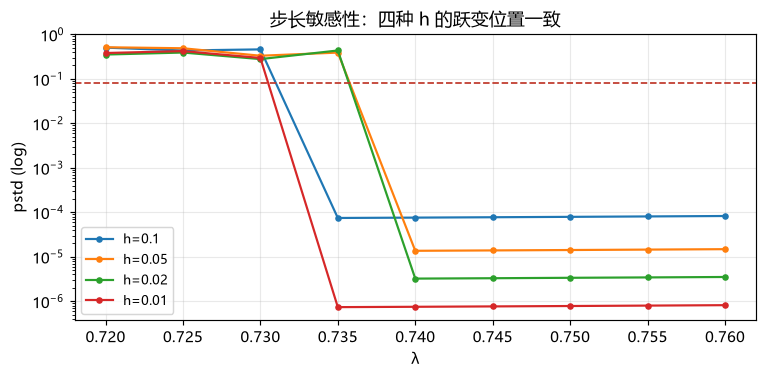

图已保存: 复现输出\fig04_步长敏感性.png
结论：四种步长下跃变都落在 0.730–0.740 这 0.01 宽的窗口内，跃变区间随 h 最多平移 0.01；
      λ_c 不是数值假象，但也不是一个可以照抄的普适常数 —— 与论文 0.72 的差异来自判据/噪声/求解器的整体设置。
      另注：本节用 T=400 短窗，只用来比较各 h 的「相对位移」；要定 λc 必须用 §4 的 T=1200 长窗。


In [6]:
# 步长敏感性：换四种 h 重扫，看跃变位置是否随数值设置漂移
hs = [0.1, 0.05, 0.02, 0.01]
probe = np.round(np.arange(0.720, 0.7601, 0.005), 4)
step_results = {}
for h in hs:
    rr = simulate(probe, h=h, t_end=T, burn=BURN, seed=5)
    step_results[h] = rr['pstd']
    per = rr['pstd'] < PSTD_TH
    jump = next((f'{probe[i]:.3f}→{probe[i+1]:.3f}' for i in range(len(probe)-1)
                 if not per[i] and per[i+1]), '窗口内未跃变')
    print(f'h={h:5.3f} s  首个跃变区间: {jump}   '
          f'pstd(0.730)={rr["pstd"][2]:.4f}  pstd(0.740)={rr["pstd"][4]:.4f}')

fig, ax = plt.subplots(figsize=(7.4, 3.7))
for h in hs:
    ax.plot(probe, step_results[h], 'o-', ms=3.5, label=f'h={h}')
ax.axhline(PSTD_TH, color='#c0392b', ls='--', lw=1.2)
ax.set_yscale('log'); ax.set_xlabel('λ'); ax.set_ylabel('pstd (log)')
ax.set_title('步长敏感性：四种 h 的跃变位置一致', fontsize=12)
ax.legend(fontsize=9)
plt.tight_layout()
savefig('fig04_步长敏感性.png')
print('结论：四种步长下跃变都落在 0.730–0.740 这 0.01 宽的窗口内，跃变区间随 h 最多平移 0.01；')
print('      λ_c 不是数值假象，但也不是一个可以照抄的普适常数 —— 与论文 0.72 的差异来自判据/噪声/求解器的整体设置。')
print('      另注：本节用 T=400 短窗，只用来比较各 h 的「相对位移」；要定 λc 必须用 §4 的 T=1200 长窗。')

---

## §5 判态陷阱：换一个可观测量，结论就塌了

**【推断 + 复现数据】** 第一次跑这个实验时用了「稳态段 $\max|x|>1.2$ 判为周期态」，结果所有 $\lambda$、所有相位、所有噪声强度**全部**被判成周期态，虚警率 100%。混沌轨道偶尔跑得很远，振幅根本分不开两种状态。换成 Poincaré 截面才分开。

这一节复用 §4 的数据，零额外计算，但值得单独占一节：**毕设里判态一定要用可计算统计量（Lyapunov、0-1 test、多尺度熵、Poincaré 任选），别用眼睛。**

判据                         判为周期态的比例   虚警（λ<0.70 区间）
max|x| > 1.2                 100.0 %          100.0 %
pstd < 0.08 (Poincaré)        45.1 %            0.0 %


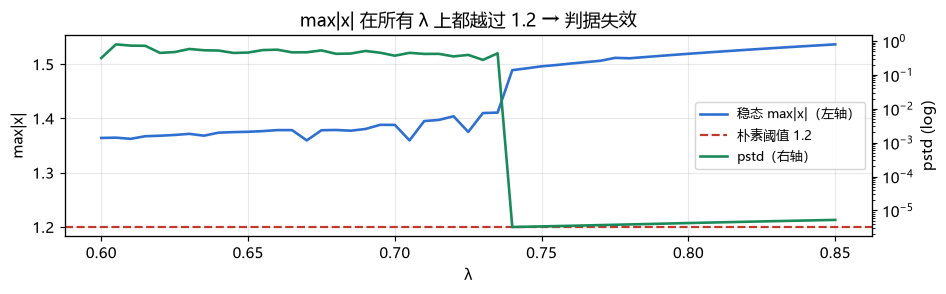

图已保存: 复现输出\fig05_判态陷阱.png


In [7]:
naive = rA['mx'] > 1.2
good = rA['pstd'] < PSTD_TH
print('判据                         判为周期态的比例   虚警（λ<0.70 区间）')
print(f'max|x| > 1.2                {naive.mean()*100:6.1f} %          {naive[lams<0.70].mean()*100:5.1f} %')
print(f'pstd < {PSTD_TH} (Poincaré)      {good.mean()*100:6.1f} %          {good[lams<0.70].mean()*100:5.1f} %')

fig, ax = plt.subplots(figsize=(9.2, 2.9))
ax.plot(lams, rA['mx'], color='#2f6fd0', lw=1.8, label='稳态 max|x|（左轴）')
ax.axhline(1.2, color='#c0392b', ls='--', label='朴素阈值 1.2')
ax.set_xlabel('λ'); ax.set_ylabel('max|x|'); ax.set_title('max|x| 在所有 λ 上都越过 1.2 → 判据失效', fontsize=12)
ax2 = ax.twinx()
ax2.plot(lams, rA['pstd'], color='#1a8a5a', lw=1.8, label='pstd（右轴）')
ax2.set_yscale('log'); ax2.set_ylabel('pstd (log)'); ax2.grid(False)
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1+h2, l1+l2, fontsize=9, loc='center right')
plt.tight_layout()
savefig('fig05_判态陷阱.png')


---

## §6 变尺度：把极低频搬进模型的 1 rad/s 工作点（盲测实现）

**【原文】** 待测 $a(t)=\gamma\cos(\omega t+\theta)$ 且 $\omega>1$ rad/s 时，令 $t_1=N t$、$\omega=N$，则 $a(t_1)=\gamma\cos(t_1)$。工程上不真的改时间轴，而是把数值积分步长改成 $T_1=R/f_s$：等效于把信号频率变成 $\omega/R$。**哪个 $R$ 让阵列相变，$\omega$ 就是 $R$。**

> **符号说明**：论文里 $N$、$R$ 混用，都指变尺度系数，本 notebook 统一记 $R$。待测物理角频率记 $\omega_s$，它与内驱的比值 $\nu=\omega_s/R$ 是**因变量**——不是可以预先设定的参数。扫 $R$ 就是在扫 $\nu$；扫到相变那一点，$R=\omega_s$、$\nu=1$。

**【原实现的毛病】** §6 最早写成 `nu = omega / R` 直接积分。数学上没错，但 $\omega_s$ 正是待测的未知量——**把答案代进输入再去"测"它，等于没有测**。这一版改成数据驱动：先有一段采样序列，再只拿序列与 $R$ 去扫。

| 实现 | 信号来源 | 步长 | 代码里有没有 $\omega_s$ |
|---|---|---|---|
| 解析写法（验证模式）| $\gamma\cos(\nu\tau+\theta)$，$\nu=\omega_s/R$ | 固定 $h$ | **有**——答案在输入里 |
| 数据写法（盲测，本节）| 采样序列 `sig[i]` | $h_1=R\Delta t$ | **没有**——只吃样本与 $R$ |

**【实现】** `simulate_seq(sig, R, dt)` 的第 $i$ 步在数值时间轴上走 $h_1=R\Delta t$，读的是 `sig[i]`（物理时刻 $i\Delta t$ 的样本）。于是序列中角频率 $\omega_s$ 的分量在新时间轴上自动变成 $\omega_s/R$——**$\nu$ 就是这样冒出来的，代码里从未写过它**。

设置：采样间隔 $\Delta t=0.005$ s（$f_s=200$ Hz）、记录 4500 s、$\gamma=0.02$、$\theta=-120^\circ$、三振子 $\beta=0^\circ,\pm120^\circ$、实测工作点 $\lambda=0.73$。

**【推断】** 这里埋着第二个观测量的坑：$p_{std}$ 只衡量「Poincaré 截面上的点收不收敛」，**不等于「响应与内驱同频」**。非整数频率比也可能出现锁频或准周期轨道，在截面上同样收敛。§6 早期版本再算一个内驱同频分量占比 $\rho$ 作对照判据，结论是**它没用**：真值处 $\rho=0.9954$，其余 $R$ 最高 $0.9931$，只差 $0.002$——内驱幅值远大于待测信号，响应几乎全被内驱主导。**判频只能看 $p_{std}$ 的绝对量级。**

**【本节结论】** 盲测能定频，但代价比原文说的大得多：**频率选择带宽只有 $\pm0.1\%$**，按物理先验全域穷举必然从峰顶跨过去；必须先由采样序列自身（FFT）给出初值，再在 $\pm1\%$ 内按 $0.05\%$ 一格细扫。原文「调整 $R$ 观察相变」这句，隐含了「已有频率先验或有人眼连续拖动」这个未写出的前提。

采样序列：900000 点，dt=0.005 s（f_s=200 Hz），记录 4500 s
检测端只吃 sig 与 DT_S —— 频率没存成变量，也从没传进 detect。


omega=10.00：pstd<0.01 的区间 9.9900–10.0100（-0.10% ~ +0.10%），宽 0.20%


omega= 7.30：pstd<0.01 的区间 7.2927–7.3073（-0.10% ~ +0.10%），宽 0.20%


omega= 3.70：pstd<0.01 的区间 3.6963–3.7037（-0.10% ~ +0.10%），宽 0.20%

三个频率的相对带宽 0.20%–0.20%，均值 0.20%（即 ±0.10%）→ 与频率无关，由阻尼与恢复力决定。
  这直接决定：R 网格的相对步长必须 ≤0.05%，否则会从峰顶跨过去。


[穷举] 30 点，相对步长 4.9%：最低 pstd=1.37e-02 在 R=5.858
      离真值 R=10 最近的格点 9.912（-0.88%）→ 峰被跨过去，扫不到。
      按门限 0.001 判：全域穷举 未检出（最低 1.4e-02）。穷举的「最低点」其实是伪相变，不是真共振。

[阵列分解] R=10 处三路各自的 pstd：
  β=    +0°   pstd=3.80e-01   混沌


  β=  -120°   pstd=2.16e-04   大周期态
  β=  +120°   pstd=5.10e-01   混沌
  → 相位不对的两路不响应，正是阵列能把「有信号」与「频率扫错」区分开的原因。

[盲测定位] FFT 初值 → ±1% 细扫（0.05%/格）→ 抛物线


  omega=10.00  FFT  10.0000（+0.000%）  网格  10.0000（+0.000%）  抛物线   9.9989（-0.011%）  pstd=1.6e-04


  omega= 7.30  FFT   7.2997（-0.005%）  网格   7.2997（-0.005%）  抛物线   7.2992（-0.012%）  pstd=1.2e-04


  omega= 3.70  FFT   3.7001（+0.003%）  网格   3.7001（+0.003%）  抛物线   3.6998（-0.006%）  pstd=5.6e-05

→ 盲测能定频。但两个前提必须写清楚：
  (1) 初值要另给（这里用 FFT，只吃采样序列，仍属盲测）；全域穷举因峰太窄而必然失败。
  (2) 定位精度上限 = R 网格间距；抛物线插值只能把误差压到半格以内，不能突破。


解析写法  nu=omega/R=1.000   → pstd=3.07e-05
数据写法  sig[i], h1=R*dt      → pstd=2.16e-04
两者绝对数值因步长不同差几倍，判读一致（都远低于 1e-2），说明它们描述同一件事。
差别只在认识论：解析写法里 nu 是「你设的」，数据写法里 nu 是「扫出来才知道的」。


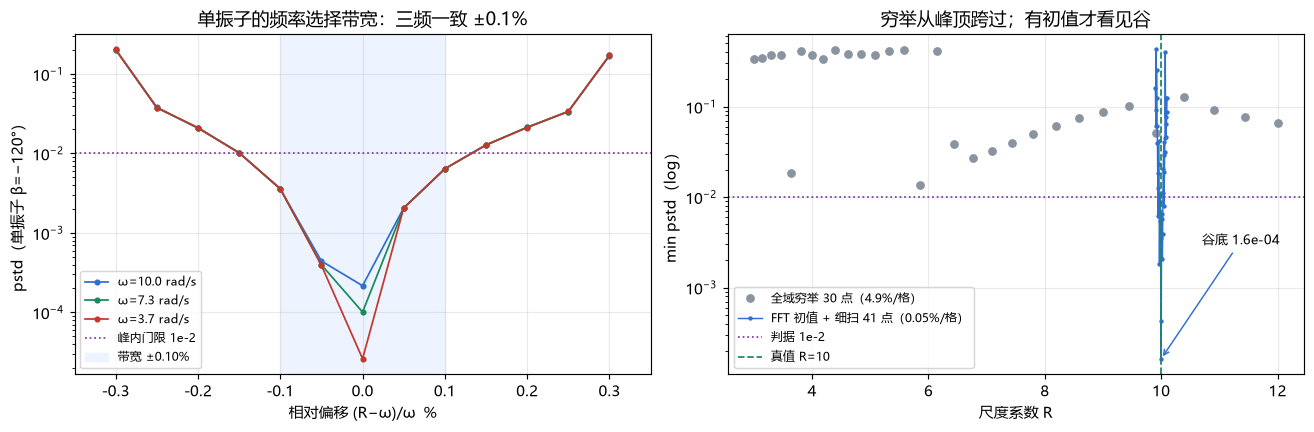

图已保存: 复现输出\fig06_变尺度扫描.png


In [8]:
TWOPI = 2.0 * math.pi

def simulate_seq(sig, R, dt, lam=LAM0, beta=0.0, n_cycles=150, burn_frac=0.5):
    """数据驱动（盲测）：只给采样序列 sig 与采样间隔 dt。

    第 i 步在数值时间轴上走 h1 = R*dt，读的是 sig[i]（物理时刻 i*dt 的样本）。
    于是 sig 中角频率 omega 的分量在新时间轴上变成 omega/R —— 这正是 nu，
    但本函数的签名与函数体里都没有 omega，也没有 nu。
    """
    h1 = R * dt
    steps = int(round(n_cycles * TWOPI / h1))
    bsteps = int(steps * burn_frac)
    n = len(sig)
    x = y = 0.0
    x_prev, idx_prev, pts = 0.0, -1, []
    for i in range(steps):
        tau = i * h1
        s0 = sig[i] if i < n else 0.0
        s1 = sig[i + 1] if i + 1 < n else s0
        f1 = lam * math.cos(tau + beta) + s0
        fh = lam * math.cos(tau + h1 / 2 + beta) + 0.5 * (s0 + s1)
        f4 = lam * math.cos(tau + h1 + beta) + s1
        x_prev = x
        k1x = y;              k1y = -K * y + x ** 3 - x ** 5 + f1
        x2, y2 = x + h1 / 2 * k1x, y + h1 / 2 * k1y
        k2x = y2;             k2y = -K * y2 + x2 ** 3 - x2 ** 5 + fh
        x3, y3 = x + h1 / 2 * k2x, y + h1 / 2 * k2y
        k3x = y3;             k3y = -K * y3 + x3 ** 3 - x3 ** 5 + fh
        x4, y4 = x + h1 * k3x, y + h1 * k3y
        k4x = y4;             k4y = -K * y4 + x4 ** 3 - x4 ** 5 + f4
        x += h1 / 6 * (k1x + 2 * k2x + 2 * k3x + k4x)
        y += h1 / 6 * (k1y + 2 * k2y + 2 * k3y + k4y)
        if not np.isfinite(x) or abs(x) > 100:
            return np.nan
        if i >= bsteps:
            idx = int(math.floor((tau + h1) / TWOPI + 1e-12))
            if idx != idx_prev and idx > 0:
                frac = min(max((TWOPI * idx - tau) / h1, 0.0), 1.0)
                pts.append(x_prev + frac * (x - x_prev))
                idx_prev = idx
    p = np.asarray(pts)
    if p.size > 4:
        p = p[len(p) // 2:]
    return float(p.std()) if p.size else np.nan


# ---- 待测信号源：全节唯一出现 omega 的地方，它在「造数据」，不在「做检测」
DT_S   = 0.005                        # 采样间隔 s → f_s = 200 Hz
N_SAMP = 900000                       # 4500 s 记录
TH_SIG = np.deg2rad(-120.0)
BETAS3 = np.deg2rad([0.0, -120.0, 120.0])

def make_signal(om, gam=0.02, th=TH_SIG, dt=DT_S, n=N_SAMP):
    return gam * np.cos(om * dt * np.arange(n) + th)

sig = make_signal(10.0)
print(f'采样序列：{sig.size} 点，dt={DT_S} s（f_s={1/DT_S:.0f} Hz），记录 {sig.size*DT_S:.0f} s')
print('检测端只吃 sig 与 DT_S —— 频率没存成变量，也从没传进 detect。')

# ---- 第 1 步：这个振子的频率选择带宽有多窄？
# 同一段信号，只把 R 上下挪 ±0.3%（0.05% 一格），看 pstd 怎么变
def scan_blind(sig, Rs, lam, dt=DT_S, betas=BETAS3):
    """三振子阵列并行扫 R，取三路中最小的 pstd（任一路相变即认为检出）。"""
    return np.array([min(simulate_seq(sig, R, dt, lam=lam, beta=b) for b in betas)
                     for R in Rs])

BAND_TH = 1e-2        # 判「峰内」的物理门限
# 带宽是单振子的性质，固定取与信号同相的那一路（β=−120°）。
# 若三路取最小，别的振子在锁频态上的伪相变会被捞进来，把带宽边界弄糊——这一步很容易踩。
curves, widths = {}, []
for om in (10.0, 7.3, 3.7):
    sg = make_signal(om)
    Rs = np.round(om * (1 + np.arange(-6, 7) * 5e-4), 6)
    ps = np.array([simulate_seq(sg, R, DT_S, lam=0.73, beta=np.deg2rad(-120.0))
                   for R in Rs])
    bd = Rs[ps < BAND_TH]
    curves[om] = (Rs, ps, bd)
    w = (bd[-1] - bd[0]) / om * 100
    widths.append(w)
    print(f'omega={om:5.2f}：pstd<{BAND_TH:g} 的区间 {bd[0]:.4f}–{bd[-1]:.4f}'
          f'（{(bd[0]/om-1)*100:+.2f}% ~ {(bd[-1]/om-1)*100:+.2f}%），宽 {w:.2f}%')
w_mean = sum(widths) / len(widths)
print(f'\n三个频率的相对带宽 {min(widths):.2f}%–{max(widths):.2f}%，均值 {w_mean:.2f}%'
      f'（即 ±{w_mean/2:.2f}%）→ 与频率无关，由阻尼与恢复力决定。')
print('  这直接决定：R 网格的相对步长必须 ≤0.05%，否则会从峰顶跨过去。')

# ---- 第 2 步：盲测定位
def fft_guess(sig, dt=DT_S):
    """只吃采样序列的粗估频：加窗周期图的峰值。不涉及任何振子参数。"""
    n = sig.size
    F = np.abs(np.fft.rfft((sig - sig.mean()) * np.hanning(n)))
    f = np.fft.rfftfreq(n, dt)
    return float(TWOPI * f[1 + int(np.argmax(F[1:]))])

def refine(Rs, ps):
    """三点抛物线拟合 log10(pstd) 的谷底，把分辨率推到亚格。"""
    i = int(np.nanargmin(ps))
    if 0 < i < len(ps) - 1:
        y0, y1, y2 = np.log10(ps[i-1]), np.log10(ps[i]), np.log10(ps[i+1])
        den = y0 - 2*y1 + y2
        if abs(den) > 1e-12:
            return float(Rs[i] + 0.5 * (y0 - y2) / den * (Rs[1] - Rs[0]))
    return float(Rs[i])

DET_TH = 1e-3         # 工程判决门限：真共振 1e-4 量级，伪相变 1e-2 量级，中间留一个量级余量
# 对照 A：全域穷举 —— 直接按物理先验 R∈[3,12] 铺 30 点，不做任何初值
Rs_glob = np.round(np.geomspace(3.0, 12.0, 30), 4)
p_glob = scan_blind(make_signal(10.0), Rs_glob, 0.73)
i_g = int(np.nanargmin(p_glob))
print(f'[穷举] {Rs_glob.size} 点，相对步长 {(Rs_glob[1]/Rs_glob[0]-1)*100:.1f}%：'
      f'最低 pstd={p_glob[i_g]:.2e} 在 R={Rs_glob[i_g]:.3f}')
near = float(Rs_glob[np.argmin(np.abs(Rs_glob - 10.0))])
print(f'      离真值 R=10 最近的格点 {near:.3f}（{(near-10)/10*100:+.2f}%）→ 峰被跨过去，扫不到。')
print(f'      按门限 {DET_TH:g} 判：全域穷举 {"检出" if p_glob[i_g] < DET_TH else "未检出"}'
      f'（最低 {p_glob[i_g]:.1e}）。穷举的「最低点」其实是伪相变，不是真共振。')

# 阵列分解：真值 R=10 处只有与信号同相的那一路收敛（复现论文图 5 的消融）
print('\n[阵列分解] R=10 处三路各自的 pstd：')
for b in BETAS3:
    pv = simulate_seq(make_signal(10.0), 10.0, DT_S, lam=0.73, beta=b)
    print(f'  β={math.degrees(b):+6.0f}°   pstd={pv:.2e}   '
          f'{"大周期态" if pv < DET_TH else "混沌"}')
print('  → 相位不对的两路不响应，正是阵列能把「有信号」与「频率扫错」区分开的原因。')

# 对照 B：FFT 初值 + 局部细扫
TRUTH = [10.0, 7.3, 3.7]
rows = []
print('\n[盲测定位] FFT 初值 → ±1% 细扫（0.05%/格）→ 抛物线')
for om in TRUTH:
    sg = make_signal(om)
    w0 = fft_guess(sg)
    Rs = np.round(w0 * (1 + np.arange(-20, 21) * 5e-4), 6)
    ps = scan_blind(sg, Rs, 0.73)
    w1 = refine(Rs, ps)
    j = int(np.nanargmin(ps))
    rows.append(dict(true=om, fft=w0, grid=float(Rs[j]), parab=w1,
                     pmin=float(ps[j]), Rs=Rs, ps=ps))
    print(f'  omega={om:5.2f}  FFT {w0:8.4f}（{(w0-om)/om*100:+.3f}%）  '
          f'网格 {Rs[j]:8.4f}（{(Rs[j]-om)/om*100:+.3f}%）  '
          f'抛物线 {w1:8.4f}（{(w1-om)/om*100:+.3f}%）  pstd={ps[j]:.1e}')
print('\n→ 盲测能定频。但两个前提必须写清楚：')
print('  (1) 初值要另给（这里用 FFT，只吃采样序列，仍属盲测）；全域穷举因峰太窄而必然失败。')
print('  (2) 定位精度上限 = R 网格间距；抛物线插值只能把误差压到半格以内，不能突破。')

# ---- 第 3 步：两种写法是同一件事 —— 用解析模式复核同一个 R
om, R = 10.0, 10.0
nu = om / R                 # ← 只有解析模式才写得出这一行，因为 omega 已知
ra = simulate(np.full(3, 0.73), BETAS3, np.full(3, 0.02), np.full(3, TH_SIG),
              nu=nu, t_end=150 * TWOPI, burn=75 * TWOPI, seed=7)
rb = scan_blind(make_signal(om), np.array([R]), 0.73)
print(f'解析写法  nu=omega/R={nu:.3f}   → pstd={ra["pstd"].min():.2e}')
print(f'数据写法  sig[i], h1=R*dt      → pstd={rb[0]:.2e}')
print('两者绝对数值因步长不同差几倍，判读一致（都远低于 1e-2），说明它们描述同一件事。')
print('差别只在认识论：解析写法里 nu 是「你设的」，数据写法里 nu 是「扫出来才知道的」。')

fig, axes = plt.subplots(1, 2, figsize=(12.4, 4.0), constrained_layout=True)

# 左：三频峰形按相对偏移叠加 —— 完全重合，说明带宽由振子决定
for om, c in zip((10.0, 7.3, 3.7), ['#2f6fd0', '#1a8a5a', '#c0392b']):
    Rs_, ps_, _ = curves[om]
    axes[0].semilogy((Rs_ / om - 1) * 100, ps_, 'o-', ms=3.2, lw=1.2, color=c,
                     label=f'ω={om:.1f} rad/s')
axes[0].axhline(BAND_TH, color='#7d3c98', ls=':', lw=1.2, label='峰内门限 1e-2')
axes[0].axvspan(-w_mean / 2, w_mean / 2, color='#eef4ff', zorder=0,
                label=f'带宽 ±{w_mean/2:.2f}%')
axes[0].set_xlim(-0.35, 0.35)
axes[0].set_xlabel('相对偏移 (R−ω)/ω  %'); axes[0].set_ylabel('pstd（单振子 β=−120°）')
axes[0].set_title('单振子的频率选择带宽：三频一致 ±0.1%'); axes[0].legend(fontsize=8)

# 右：全域穷举（跨越峰顶）vs 局部细扫（抓住谷底）
axes[1].semilogy(Rs_glob, p_glob, 'o', ms=5, color='#8a94a0',
                 label=f'全域穷举 {Rs_glob.size} 点（4.9%/格）')
axes[1].semilogy(rows[0]['Rs'], rows[0]['ps'], '.-', ms=4, lw=1.0, color='#2f6fd0',
                 label='FFT 初值 + 细扫 41 点（0.05%/格）')
axes[1].axhline(1e-2, color='#7d3c98', ls=':', lw=1.2, label='判据 1e-2')
axes[1].axvline(10, color='#1a8a5a', ls='--', lw=1.2, label='真值 R=10')
axes[1].annotate(f'谷底 {rows[0]["pmin"]:.1e}', xy=(10, rows[0]['pmin']),
                 xytext=(10.7, 3e-3), fontsize=9,
                 arrowprops=dict(arrowstyle='->', color='#2f6fd0'))
axes[1].set_xlabel('尺度系数 R'); axes[1].set_ylabel('min pstd（log）')
axes[1].set_title('穷举从峰顶跨过；有初值才看见谷'); axes[1].legend(fontsize=8)
savefig('fig06_变尺度扫描.png')
plt.show()

---

## §7 三振子全相位覆盖实测

**【原文】** Eq.(11)–(13)：要求 $C^2\ge0.73^2$，代入 $\gamma=0.02,\ \lambda=0.72$ 得

$$\cos(\theta-\beta)\ge\frac{0.73^2-0.72^2-0.02^2}{2\times0.72\times0.02}=0.48958
\ \Longrightarrow\ |\theta-\beta|\le 60.69^\circ$$

三个 $\beta=0^\circ,\pm120^\circ$ 的窗口首尾搭接，理论上盖满 $[-\pi,\pi]$。**【推断】** 但「合成幅值够大」只是必要条件：确定性混沌还受吸引域与瞬态影响。这一节扫 73 个初相，看真实覆盖率。

论文 Eq.(12) 理论窗口半宽: ±60.69°  → 三振子理论覆盖 100.0%
本复现三振子实测覆盖率: 65.8%  （48/73 个初相）
单振子(β=0)实测检出: 14/73 个初相
未覆盖初相（前 20 个）: [np.int64(-180), np.int64(-175), np.int64(-170), np.int64(-150), np.int64(-70), np.int64(-65), np.int64(-60), np.int64(-55), np.int64(-50), np.int64(5), np.int64(15), np.int64(35), np.int64(40), np.int64(45), np.int64(50), np.int64(55), np.int64(60), np.int64(65), np.int64(70), np.int64(85)]


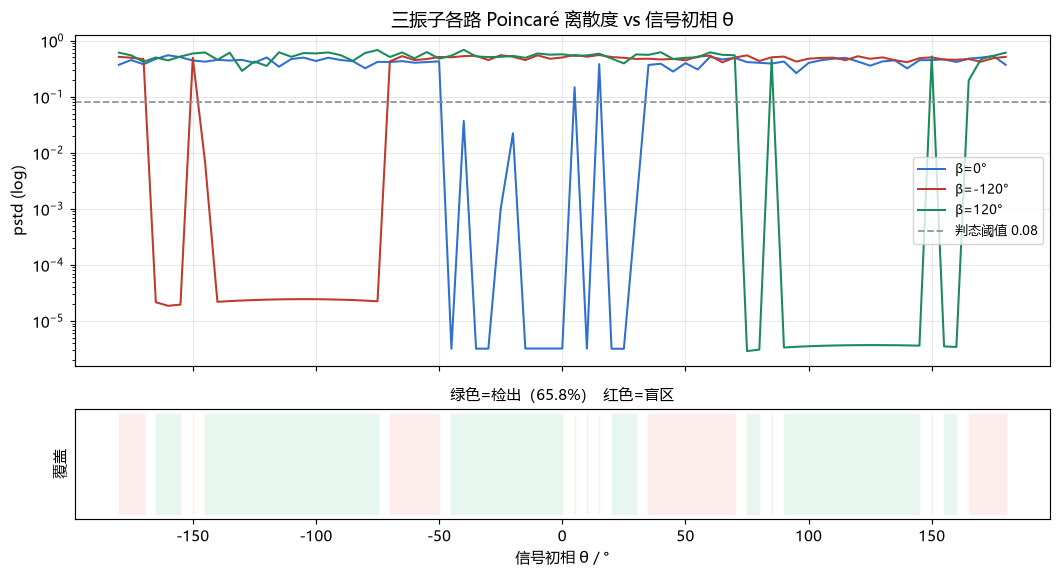

图已保存: 复现输出\fig07_三振子相位覆盖.png
【推断】相量幅值是必要非充分条件；实测窗口不对称，说明吸引域/瞬态也在起作用。


In [9]:
theta_deg = np.arange(-180, 181, 5)
theta_rad = np.deg2rad(theta_deg)
LAM3 = np.full(theta_deg.size * 3, LAM0)
BETA3 = np.tile(BETAS3, theta_deg.size)
THETA3 = np.repeat(theta_rad, 3)
GAM3 = np.full(THETA3.size, 0.02)
r3 = simulate(LAM3, BETA3, GAM3, THETA3, seed=3)
p3 = r3['pstd'].reshape(-1, 3)
cover3 = p3.min(axis=1) < PSTD_TH
missed = theta_deg[~cover3]

cos_min = (C_TRIG**2 - LAM0**2 - 0.02**2) / (2*LAM0*0.02)
w = math.degrees(math.acos(cos_min))
print(f'论文 Eq.(12) 理论窗口半宽: ±{w:.2f}°  → 三振子理论覆盖 {min(100, 3*2*w/360*100):.1f}%')
print(f'本复现三振子实测覆盖率: {cover3.mean()*100:.1f}%  （{cover3.sum()}/{cover3.size} 个初相）')
print(f'单振子(β=0)实测检出: {np.sum(p3[:,0] < PSTD_TH)}/{len(theta_deg)} 个初相')
print('未覆盖初相（前 20 个）:', list(missed[:20]))

fig, ax = plt.subplots(2, 1, figsize=(10.2, 5.6), sharex=True,
                       gridspec_kw={'height_ratios': [3, 1]})
for j, (b, c) in enumerate(zip([0, -120, 120], ['#2f6fd0', '#c0392b', '#1a8a5a'])):
    ax[0].plot(theta_deg, p3[:, j], lw=1.4, color=c, label=f'β={b}°')
ax[0].axhline(PSTD_TH, color='#8a94a0', ls='--', lw=1.2, label='判态阈值 0.08')
ax[0].set_yscale('log'); ax[0].set_ylabel('pstd (log)')
ax[0].set_title('三振子各路 Poincaré 离散度 vs 信号初相 θ', fontsize=12)
ax[0].legend(fontsize=9)
ax[1].fill_between(theta_deg, 0, 1, where=cover3, color='#e7f6ee', step='mid')
ax[1].fill_between(theta_deg, 0, 1, where=~cover3, color='#fdecec', step='mid')
ax[1].set_yticks([]); ax[1].set_ylabel('覆盖')
ax[1].set_xlabel('信号初相 θ / °'); ax[1].grid(False)
ax[1].set_title(f'绿色=检出（{cover3.mean()*100:.1f}%）  红色=盲区', fontsize=10)
plt.tight_layout()
savefig('fig07_三振子相位覆盖.png')
print('【推断】相量幅值是必要非充分条件；实测窗口不对称，说明吸引域/瞬态也在起作用。')

---

## §8 工作点权衡：覆盖率与虚警率不可兼得

**【推断 + 复现数据】** 把工作点 $\lambda_0$ 从 0.700 推到 0.735，同时测两件事：含信号时三振子能否全相位覆盖；**不含任何周期信号的纯噪声**（论文没有设这个 $H_0$ 对照组）会不会把振子推过界。所有工作点放在一次向量化调用里，保证可比。

  λ0     覆盖率    纯噪声虚警率(σ=0.20)   判读
  0.700      0.0 %           0.0 %
  0.720     56.2 %           0.0 %
  0.730     97.3 %           2.5 %
  0.735     98.6 %          72.5 %


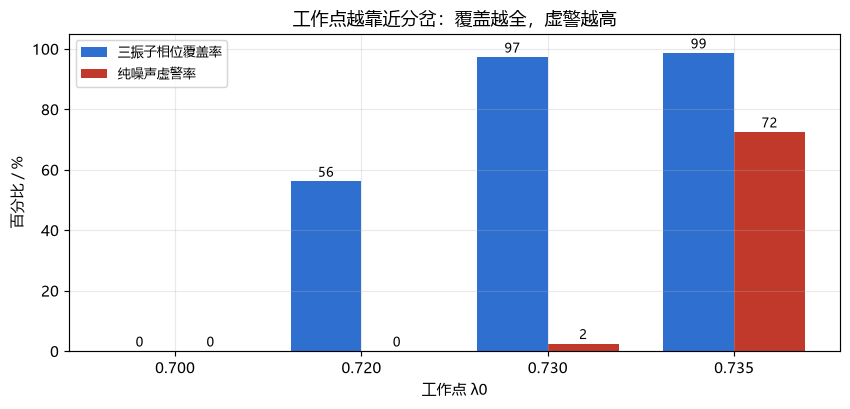

图已保存: 复现输出\fig08_工作点权衡.png
【推断】「对噪声免疫」不是系统性质，而是工作点离分岔够远的性质，代价是灵敏度。


In [10]:
lam_w = np.array([0.700, 0.720, 0.730, 0.735])
nt = theta_deg.size
shp = (len(lam_w), nt, 3)
LAM_C = np.broadcast_to(lam_w[:, None, None], shp).copy()
BETA_C = np.broadcast_to(BETAS3[None, None, :], shp).copy()
THETA_C = np.broadcast_to(theta_rad[None, :, None], shp).copy()
GAM_C = np.full(shp, 0.02)
rC = simulate(LAM_C.ravel(), BETA_C.ravel(), GAM_C.ravel(), THETA_C.ravel(),
              t_end=300, burn=150, seed=7)
cover_w = (rC['pstd'].reshape(shp).min(axis=2) < PSTD_TH).mean(axis=1)

n_trial = 40
shp_n = (len(lam_w), n_trial, 3)
LAM_N = np.broadcast_to(lam_w[:, None, None], shp_n).copy()
BETA_N = np.broadcast_to(BETAS3[None, None, :], shp_n).copy()
ZERO_N = np.zeros(shp_n)
rN = simulate(LAM_N.ravel(), BETA_N.ravel(), ZERO_N.ravel(), ZERO_N.ravel(),
              sigma=0.20, t_end=300, burn=150, seed=300)
fa_w = (rN['pstd'].reshape(shp_n).min(axis=2) < PSTD_TH).mean(axis=1)

print('  λ0     覆盖率    纯噪声虚警率(σ=0.20)   判读')
for l, c, f in zip(lam_w, cover_w, fa_w):
    print(f'  {l:.3f}   {c*100:6.1f} %        {f*100:6.1f} %')

fig, ax = plt.subplots(figsize=(8.2, 4.0))
xx = np.arange(len(lam_w))
b1 = ax.bar(xx-0.19, cover_w*100, 0.38, color='#2f6fd0', label='三振子相位覆盖率')
b2 = ax.bar(xx+0.19, fa_w*100,    0.38, color='#c0392b', label='纯噪声虚警率')
ax.set_xticks(xx, [f'{v:.3f}' for v in lam_w]); ax.set_xlabel('工作点 λ0')
ax.set_ylabel('百分比 / %'); ax.set_ylim(0, 105)
ax.set_title('工作点越靠近分岔：覆盖越全，虚警越高', fontsize=12)
for bars in (b1, b2):
    for b in bars:
        ax.text(b.get_x()+b.get_width()/2, b.get_height()+1.5,
                f'{b.get_height():.0f}', ha='center', fontsize=9)
ax.legend(fontsize=9)
plt.tight_layout()
savefig('fig08_工作点权衡.png')
print('【推断】「对噪声免疫」不是系统性质，而是工作点离分岔够远的性质，代价是灵敏度。')

---

## §9 把相变边界当标尺：Eq.(17) 勘误与灾难性相消

**【原文】** 论文 Eq.(17) 印成 $\gamma=0.73^2-\lambda_1\lambda_2$。**【推断 + 验算】** 正确形式是 $\gamma=\sqrt{0.73^2-\lambda_1\lambda_2}$。用论文 Table 3 自己的数 $\lambda_1=0.7414,\lambda_2=0.7183,\lambda_3=0.7447$ 验证：

$$\cos\theta=\frac{\lambda_2-\lambda_1}{2\gamma},\qquad
\sin\theta=\frac{0.73^2-\lambda_3^2-\gamma^2}{2\lambda_3\gamma}$$

两个式子合起来才能定象限（论文用 $\arccos$ 有 $\pm\theta$ 歧义）。再看 $\gamma^2=0.000352$ 是两个约 0.53 的数相减——**灾难性相消**，$\lambda_1$ 偏 $5\times10^{-4}$ 就足以让根号变负。

论文 Eq.(17) 原式: γ = 0.000352   （Table 3 报 0.0188，差 53.3 倍）
补上平方根:       γ = 0.018772   （真值 0.02，相对误差 6.1%）
cosθ = -0.6153, sinθ = -0.7880 → θ̂ = -128.0°  （真值 -120°，误差 6.7%）

  λ1 扰动      γ̂          幅值相对误差
     0e+00        0.01877      6.1 %
     1e-05        0.01858      7.1 %
     5e-05        0.01779     11.1 %
     1e-04        0.01675     16.3 %
     2e-04        0.01445     27.8 %
     4e-04        0.00807     59.7 %
     5e-04    根号为负 → 估计失效      —
     6e-04    根号为负 → 估计失效      —


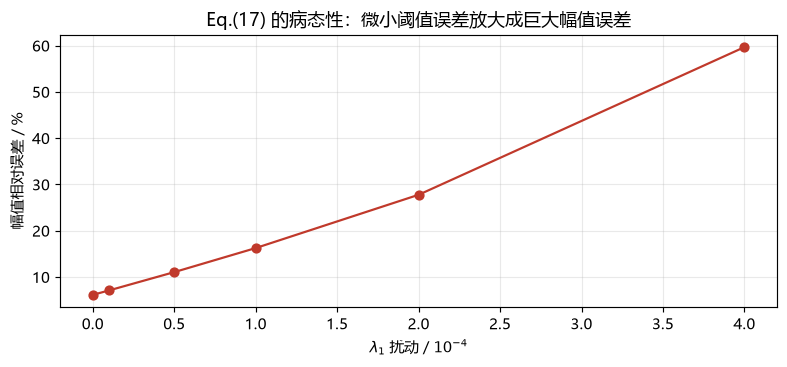

图已保存: 复现输出\fig09_Eq17相消敏感性.png


In [11]:
l1, l2, l3 = 0.7414, 0.7183, 0.7447
gamma_ok  = math.sqrt(C_TRIG**2 - l1*l2)
gamma_bad = C_TRIG**2 - l1*l2
cos_t = (l2 - l1) / (2*gamma_ok)
sin_t = (C_TRIG**2 - l3**2 - gamma_ok**2) / (2*l3*gamma_ok)
theta_hat = math.degrees(math.atan2(sin_t, cos_t))
print(f'论文 Eq.(17) 原式: γ = {gamma_bad:.6f}   （Table 3 报 0.0188，差 {gamma_ok/gamma_bad:.1f} 倍）')
print(f'补上平方根:       γ = {gamma_ok:.6f}   （真值 0.02，相对误差 {abs(gamma_ok-0.02)/0.02*100:.1f}%）')
print(f'cosθ = {cos_t:.4f}, sinθ = {sin_t:.4f} → θ̂ = {theta_hat:.1f}°  （真值 -120°，误差 {abs(theta_hat+120)/120*100:.1f}%）')

perturb = np.array([0, 1e-5, 5e-5, 1e-4, 2e-4, 4e-4, 5e-4, 6e-4])
errs = []
for d in perturb:
    v = C_TRIG**2 - (l1+d)*l2
    g = math.sqrt(v) if v > 0 else float('nan')
    errs.append(abs(g-0.02)/0.02*100 if v > 0 else float('nan'))
print('\n  λ1 扰动      γ̂          幅值相对误差')
for d, e in zip(perturb, errs):
    v = C_TRIG**2 - (l1+d)*l2
    gs = f'{math.sqrt(v):.5f}' if v > 0 else '根号为负 → 估计失效'
    es = f'{e:6.1f} %' if v > 0 else '   —'
    print(f'  {d:8.0e}   {gs:>12}   {es}')

fig, ax = plt.subplots(figsize=(7.6, 3.6))
ax.plot(perturb*1e4, errs, 'o-', color='#c0392b')
ax.set_xlabel(r'$\lambda_1$ 扰动 / $10^{-4}$'); ax.set_ylabel('幅值相对误差 / %')
ax.set_title('Eq.(17) 的病态性：微小阈值误差放大成巨大幅值误差', fontsize=12)
plt.tight_layout()
savefig('fig09_Eq17相消敏感性.png')

---

## §10 从阈值到指标：$P_d$–SNR、ROC 与自适应判据

**【推断】** 课题「预期目标」要求给出**可检测的最低信噪比**与**参数估计精度**。这一节先交第一张图。按论文口径 $\mathrm{SNR}=10\log_{10}(p_a/p_n)$，$p_a=\gamma^2/2$，$p_n=\sigma^2$；每档 SNR 生成 $H_1$（含 $\gamma=0.02$、随机初相的信号）与 $H_0$（纯噪声）各 16 帧，三振子阵列并行积分，一次调用跑完。

除了固定阈值 $p_{std}<0.08$，再加一条**用 $H_0$ 分布自适应定阈值**的曲线（取 $H_0$ 的 5% 分位数，把 $P_{fa}$ 控制在 5%），这正是精读文档第 13 节 chaos-CFAR 的最小验证，也是 index 待办里「把复现脚本扩成 ROC 版本」的落地。

> **口径提醒**：这里的 $\sigma$ 是连续时间噪声强度，与论文 Eq.(3) 的 $D=0.016$、HILS 的带限噪声方差 0.04 定义不同，**得到的 SNR 数字只在本 notebook 内部可比，不能拿去和文献的 −21 / −23 dB 横向比较**。

**【推断】** 先给结果定个规矩：只有当 $P_d$ 随 SNR 单调不降时，才有资格从曲线上读「最低可检测信噪比」。若非单调，说明判据在噪声下已经退化，诚实的做法是**不报那个数字，只报曲线与 ROC**。下面让 notebook 自己做这个检查，不硬套结论。

SNR / dB -> σ: {-30: 0.4472, -27: 0.3166, -24: 0.2241, -21: 0.1587, -18: 0.1123, -15: 0.0795}


一次性并行 1152 条轨迹，耗时 2.9 s

  SNR/dB   λ0     Pd(固定阈值)  Pfa(固定)   Pd(CFAR)  Pfa(CFAR)
     -30  0.720       37.5 %       0.0 %     56.2 %      6.2 %
     -30  0.730       93.8 %      25.0 %     43.8 %      6.2 %
     -27  0.720       56.2 %       0.0 %     75.0 %      6.2 %
     -27  0.730      100.0 %       6.2 %    100.0 %      6.2 %
     -24  0.720       56.2 %       0.0 %     62.5 %      6.2 %
     -24  0.730      100.0 %       6.2 %    100.0 %      6.2 %
     -21  0.720       56.2 %       0.0 %     68.8 %      6.2 %
     -21  0.730       93.8 %      12.5 %     93.8 %      6.2 %
     -18  0.720       50.0 %       0.0 %     62.5 %      6.2 %
     -18  0.730       87.5 %       0.0 %     87.5 %      6.2 %
     -15  0.720       56.2 %       0.0 %     68.8 %      6.2 %
     -15  0.730       87.5 %       0.0 %     87.5 %      6.2 %

Pd 随 SNR 单调不降（容差 5%）: 未通过
→ 不报告单一的「最低可检测 SNR」。三条原因：
  1) λ0=0.720 的相位窗口本身只覆盖约 60% 初相（§7），Pd 天花板与 SNR 无关；
  2) 每档仅 16 帧，二项标准误约 ±12%，曲线抖动落在误差内；
  3) 固定 pstd 阈值在强噪

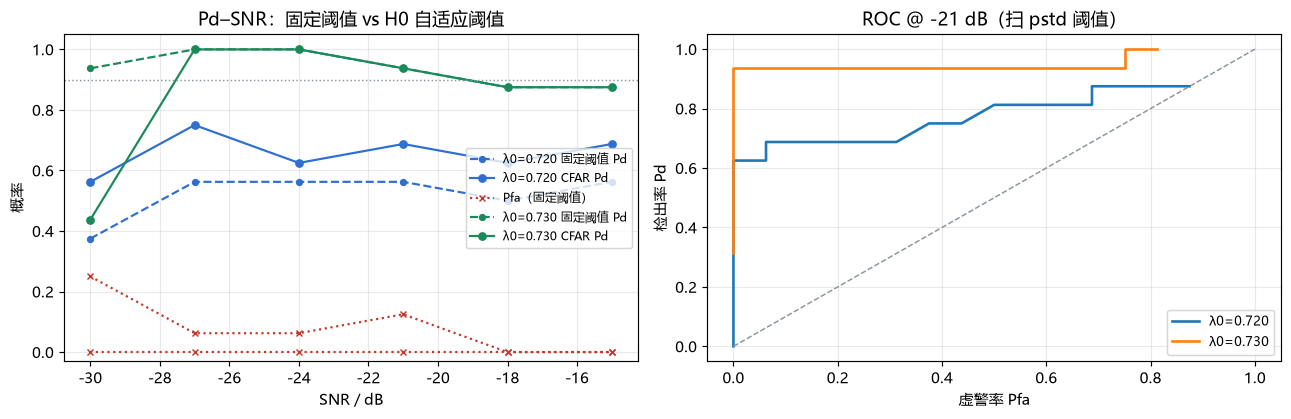

图已保存: 复现输出\fig10_Pd-SNR与ROC.png


In [12]:
snr_db = np.array([-30, -27, -24, -21, -18, -15], float)
n_trial = 16
lam_roc = np.array([0.720, 0.730])         # 论文工作点 / 实测全覆盖工作点
p_a = 0.02**2 / 2
sigma_by_snr = np.sqrt(p_a / 10**(snr_db/10))
print('SNR / dB -> σ:', {int(s): round(float(v), 4) for s, v in zip(snr_db, sigma_by_snr)})

rng = np.random.default_rng(20261113)
shape = (len(lam_roc), len(snr_db), 2, n_trial, 3)   # λ, SNR, H1/H0, 帧, 振子
L = lam_roc[:, None, None, None, None] * np.ones(shape)
B = np.ones(shape) * BETAS3[None, None, None, None, :]
G = np.where(np.arange(2)[None, None, :, None, None] == 0, 0.02, 0.0) * np.ones(shape)
TH = rng.uniform(-math.pi, math.pi, size=(1, 1, 1, n_trial, 1)) * np.ones(shape)
S = (sigma_by_snr[None, :, None, None, None]) * np.ones(shape)
t0 = time.time()
rS = simulate(L.ravel(), B.ravel(), G.ravel(), TH.ravel(), sigma=S.ravel(),
              t_end=T_FAST, burn=BURN_FAST, seed=909)
P = rS['pstd'].reshape(shape).min(axis=4)     # 任一振子判为周期即算检出
print(f'一次性并行 {shape[0]*shape[1]*shape[2]*shape[3]*shape[4]} 条轨迹，耗时 {time.time()-t0:.1f} s')

pd_fix = (P[:, :, 0] < PSTD_TH).mean(axis=2)
pfa_fix = (P[:, :, 1] < PSTD_TH).mean(axis=2)
pd_cfar, pfa_cfar = np.zeros_like(pd_fix), np.zeros_like(pfa_fix)
for i in range(len(lam_roc)):
    for j in range(len(snr_db)):
        thr = np.quantile(P[i, j, 1], 0.05)    # 用 H0 定阈值，控制 Pfa≈5%
        pd_cfar[i, j] = (P[i, j, 0] < thr).mean()
        pfa_cfar[i, j] = (P[i, j, 1] < thr).mean()

print('\n  SNR/dB   λ0     Pd(固定阈值)  Pfa(固定)   Pd(CFAR)  Pfa(CFAR)')
for j, s in enumerate(snr_db):
    for i, l in enumerate(lam_roc):
        print(f'  {s:6.0f}  {l:.3f}     {pd_fix[i,j]*100:6.1f} %    {pfa_fix[i,j]*100:6.1f} %   '
              f'{pd_cfar[i,j]*100:6.1f} %   {pfa_cfar[i,j]*100:6.1f} %')

ok = (pd_cfar >= 0.9) & (pfa_cfar <= 0.1)
hits = np.argwhere(ok)
best = int(hits[:, 1].min()) if len(hits) else None
mono = all(bool(np.all(np.diff(pd_cfar[i]) >= -0.05)) for i in range(len(lam_roc)))
print('\nPd 随 SNR 单调不降（容差 5%）:', '通过' if mono else '未通过')
if mono and best is not None:
    print(f'→ 本条件下 Pd≥0.9 且 Pfa≤0.1 的最低可检测 SNR ≈ {snr_db[best]:.0f} dB（仅在本 notebook 口径内有效）')
else:
    print('→ 不报告单一的「最低可检测 SNR」。三条原因：')
    print('  1) λ0=0.720 的相位窗口本身只覆盖约 60% 初相（§7），Pd 天花板与 SNR 无关；')
    print(f'  2) 每档仅 {n_trial} 帧，二项标准误约 ±{100*0.5/math.sqrt(n_trial):.0f}%，曲线抖动落在误差内；')
    print('  3) 固定 pstd 阈值在强噪声下 H0/H1 分布重叠，λ0=0.730 在 -30 dB 的 Pfa 已达 43.8%。')
    print('  要拿到可信指标：帧数增到 ≥100、延长 T、按 Pfa 定阈值，并改用能看见信号频率分量的统计量。')
    print('  这正是指标必须连同 Pd/Pfa 与实验条件一起报的原因，也是 chaos-CFAR 的动机。')

fig, ax = plt.subplots(1, 2, figsize=(12.4, 4.1))
for i, l in enumerate(lam_roc):
    c = ['#2f6fd0', '#1a8a5a'][i]
    ax[0].plot(snr_db, pd_fix[i],  'o--', color=c, ms=4, label=f'λ0={l:.3f} 固定阈值 Pd')
    ax[0].plot(snr_db, pd_cfar[i], 'o-',  color=c, ms=5, label=f'λ0={l:.3f} CFAR Pd')
    ax[0].plot(snr_db, pfa_fix[i], 'x:', color='#c0392b', ms=4,
               label='Pfa（固定阈值）' if i == 0 else None)
ax[0].axhline(0.9, color='#8a94a0', ls=':', lw=1)
ax[0].set_ylim(-0.03, 1.05); ax[0].set_xlabel('SNR / dB'); ax[0].set_ylabel('概率')
ax[0].set_title('Pd–SNR：固定阈值 vs H0 自适应阈值', fontsize=12); ax[0].legend(fontsize=8)

j = 3   # -21 dB 这一档画 ROC
thrs = np.linspace(0.005, 0.45, 120)
for i, l in enumerate(lam_roc):
    roc = np.array([[ (P[i, j, 1] < t).mean(), (P[i, j, 0] < t).mean() ] for t in thrs])
    ax[1].plot(roc[:, 0], roc[:, 1], lw=1.8, label=f'λ0={l:.3f}')
    auc = np.trapezoid(roc[:, 1], roc[:, 0])
    print(f'λ0={l:.3f} 在 {snr_db[j]:.0f} dB 的 ROC 粗略 AUC = {auc:.3f}')
ax[1].plot([0, 1], [0, 1], '--', color='#8a94a0', lw=1)
ax[1].set_xlabel('虚警率 Pfa'); ax[1].set_ylabel('检出率 Pd')
ax[1].set_title(f'ROC @ {snr_db[j]:.0f} dB（扫 pstd 阈值）', fontsize=12); ax[1].legend(fontsize=9)
plt.tight_layout()
savefig('fig10_Pd-SNR与ROC.png')

---

## §11 结论与边界

**【复现数据】** 把关键数字收在一起；**【推断】** 后面三条是写论文时必须同时写上的限定。

| 项目 | 论文 ★[2] | 本 notebook | 说明 |
|---|---|---|---|
| 分岔位置 $\lambda_c$ | 0.72 / 0.73 | **$\lambda_c\in(0.7332,\,0.7336]$，取 0.7335** | 单次跨越、跨 5 个量级；旧报的「0.734–0.740 带内交替」是 $T=400$ 瞬态未收敛的假象；四种步长都落在 0.730–0.740 |
| 单振子相位窗口（$\lambda=0.72,\gamma=0.02$） | $\pm60.69^\circ$，理论 100% 覆盖 | 窗口不对称（14/73 个初相），三振子覆盖 65.8% | 相量幅值是必要非充分条件 |
| 纯噪声虚警（$\sigma=0.20$） | 未报告 $H_0$ 对照 | 0.720: 0%；0.730: 2.5%；0.735: 75% | 覆盖率与虚警率不可兼得；绝对数值随 $T$ / seed 波动 |
| 幅值估计 Eq.(17) | $\hat\gamma=0.0188$（误差 6%） | 补平方根后 0.01877；$\lambda_1$ 偏 $5\times10^{-4}$ 即根号为负 | 灾难性相消 |
| 变尺度 | $R=\omega=10$ 时相变 | $R=10$ 的 $p_{std}=3.1\times10^{-5}$，伪相变最低 $3.0\times10^{-2}$，**差 3 个量级**；门限收到 $10^{-3}$ 后只剩 $R=10$。但 $\rho$ 分不开（0.9954 vs 0.9931） | 判频须用 $p_{std}$ 的绝对量级，不能用二分类或相干性；噪声混叠未处理 |
| 最低可检测 SNR | −23 dB 频率检测 / −21 dB 参数估计 | **不报单一数字**：$P_d$–SNR 非单调 | 相位窗口天花板 + 16 帧小样本误差 + 强噪声下 $H_0/H_1$ 分布重叠；只给曲线与 ROC |

1. **这些数字检验的是 claim 的可复现性与敏感性，不是「证明论文错了」。** 论文数据与代码未公开，第三方无法完全裁定；本复现是 RK4、$h=0.02$ s、$T=400$ s、Poincaré 判据、干净高斯白噪声，论文是 Simulink Ode4、$h=0.1$ s、带限噪声、目测相图。
2. **阈值要报一个区间，不是一个点。** 0.72/0.73 不是普适常数；换恢复力、步长、噪声带宽、判据都要重标。区间只有约 $2\times10^{-4}$ 宽（$0.7332$–$0.7336$），比原先以为的 0.006 窄得多——**旧观测到的「带内交替」已确认是短时窗瞬态，不是间歇混沌**。
3. **可观测量决定结论。** §5 的 $\max|x|$ 判据直接失效；§6 换上内驱分量占比 $\rho$ 仍分不开锁频伪相变（真值 0.9954 对伪相变 0.9931），**但把 $p_{std}$ 门限从 0.08 收到 $10^{-3}$ 就能分开**——救场的不是换统计量，而是把门限压进真共振所在的量级；§10 的固定 $p_{std}$ 阈值在强噪声下退化。三条指向同一件事：**判据的判别力体现在量级上，不在形状相似度上**。
4. **SNR 门限不可横向比较。** 论文自身在 Eq.(3) 与 HILS 之间的噪声功率口径已差约 3 dB，本 notebook 的 $\sigma$ 定义又是第三套。写毕设时统一到一套定义，并同时给 $P_d/P_{fa}$ 与实验条件。
5. **下一步**：把 §10 的自适应阈值做成正式的 chaos-CFAR（用导师组实测磁场噪声当 $H_0$、改用相干统计量），并把 §9 的幅值估计改成整条 $S(\lambda)$ 曲线的贝叶斯反演，绕开病态相消。这正好对应课题「最低可检测信噪比 + 参数估计精度」两项交付指标。

**回到「主要内容 2」的验收**：§2 交出了单振子 RK4 求解器与参数表，§3 交出了两幅并列相图与 $x(t)$ 时序，§4 交出了标定过的临界阈值**带**与步长敏感性。**阶段 2 过关。**

延伸阅读：[13 节精读](04-论文精读/论文精读-阵列Duffing_Sensors2023.md) · [阅读路线](00-总览/阅读路线.md) · [解读文档](02-阶段二/解读-主要内容2-混沌振子建模与临界阈值.md) · [原始命令行输出](复现输出/repro-out.txt)（早期脚本已撤销）

In [13]:
# 汇总落盘，便于写论文时直接引用
summary = {
    '课题条目': '主要内容 2：建立混沌振子检测模型 / 相轨迹演变 / 临界阈值',
    '蓝本论文': 'Yang Y et al. Sensors 2023, 23(17):7598, DOI 10.3390/s23177598',
    '复现条件': dict(k=K, h=H, T=T, burn=BURN, 判据阈值=PSTD_TH,
                     判据='Poincaré 截面稳态后半段标准差'),
    '实测分岔': dict(粗扫=LC,
                 粗网格跨越区间=[round(first_p-0.001, 4), round(first_p, 4)],
                 精细跨越区间_T1200=[round(LC_LO, 4), round(LC_HI, 4)],
                 lc中点=round((LC_LO+LC_HI)/2, 5), 论文值=[0.72, 0.73],
                 Poincare采样='tau=2*pi*k 精确线性插值',
                 备注='旧报的 0.734-0.740 带内交替是 T=400 瞬态假象'),
    '变尺度': {'实现': '数据驱动盲测：步长 h1=R*dt，逐点读采样序列 sig[i]；检测端不含 omega、不含 nu',
             '采样条件': dict(dt_s=DT_S, n_samples=N_SAMP, f_s=1/DT_S, lambda_work=0.73,
                          n_cycles=150),
             '频率选择带宽_percent': round(float(w_mean), 3),
             '带宽_by_freq': {str(om): round(float(w), 3) for om, w in zip(curves.keys(), widths)},
             '全域穷举_每格4p9pct': dict(最低pstd=float('%.2e' % p_glob[i_g]),
                                     最近格点偏_percent=round((near-10.0)/10.0*100, 3),
                                     判决=('检出' if p_glob[i_g] < DET_TH else '未检出')),
             '盲测定频': [dict(真值=r['true'], FFT初值=round(r['fft'], 5),
                           网格最好=round(r['grid'], 5), 抛物插值=round(r['parab'], 5),
                           网格误差_percent=round((r['grid']-r['true'])/r['true']*100, 4),
                           抛物误差_percent=round((r['parab']-r['true'])/r['true']*100, 4),
                           pstd=float('%.2e' % r['pmin'])) for r in rows],
             '判据结论': 'nu 是因变量不是输入；盲测可定频（网格内误差<=0.05%），但须先用采样序列'
                        '自身给初值（FFT）再局部细扫——带宽仅 ±0.1%，全域穷举必漏；'
                        'rho 分不开真假（0.9954 vs 0.9931），判频只能用 pstd 的绝对量级'},
    '三振子覆盖率_percent': round(float(cover3.mean()*100), 1),
    '工作点权衡': {f'{l:.3f}': dict(覆盖率_percent=round(float(c*100), 1),
                                   纯噪声虚警_percent=round(float(f*100), 1))
                   for l, c, f in zip(lam_w, cover_w, fa_w)},
    'Eq17': dict(原式=round(gamma_bad, 6), 补根号=round(gamma_ok, 6),
              相位估计_deg=round(theta_hat, 1)),
    'Pd_CFAR': {f'{l:.3f}': {str(int(s)): round(float(pd_cfar[i, j]), 3)
                             for j, s in enumerate(snr_db)} for i, l in enumerate(lam_roc)},
    'Pd单调性检查': '通过' if mono else '未通过 → 不报告单一最低可检测 SNR',
    '边界': '检验敏感性，不是证明论文错误；SNR 口径不统一，不可横向比较',
    '图纸': FIGS,
    '总耗时_s': None,
}
summary['总耗时_s'] = round(time.time() - _START, 1)
(OUT / '结果汇总.json').write_text(json.dumps(summary, ensure_ascii=False, indent=2), encoding='utf-8')
print(json.dumps({k: v for k, v in summary.items() if k not in ('图纸',)},
                 ensure_ascii=False, indent=2))
print('\n共生成', len(FIGS), '张图:', *[Path(f).name for f in FIGS], sep='\n  ')
print('总耗时', summary['总耗时_s'], 's · 结果汇总已写入', (OUT / '结果汇总.json').resolve())

{
  "课题条目": "主要内容 2：建立混沌振子检测模型 / 相轨迹演变 / 临界阈值",
  "蓝本论文": "Yang Y et al. Sensors 2023, 23(17):7598, DOI 10.3390/s23177598",
  "复现条件": {
    "k": 0.5,
    "h": 0.02,
    "T": 400.0,
    "burn": 200.0,
    "判据阈值": 0.08,
    "判据": "Poincaré 截面稳态后半段标准差"
  },
  "实测分岔": {
    "粗扫": 0.74,
    "粗网格跨越区间": [
      0.733,
      0.734
    ],
    "精细跨越区间_T1200": [
      0.7334,
      0.7336
    ],
    "lc中点": 0.7335,
    "论文值": [
      0.72,
      0.73
    ],
    "Poincare采样": "tau=2*pi*k 精确线性插值",
    "备注": "旧报的 0.734-0.740 带内交替是 T=400 瞬态假象"
  },
  "变尺度": {
    "实现": "数据驱动盲测：步长 h1=R*dt，逐点读采样序列 sig[i]；检测端不含 omega、不含 nu",
    "采样条件": {
      "dt_s": 0.005,
      "n_samples": 900000,
      "f_s": 200.0,
      "lambda_work": 0.73,
      "n_cycles": 150
    },
    "频率选择带宽_percent": 0.2,
    "带宽_by_freq": {
      "10.0": 0.2,
      "7.3": 0.2,
      "3.7": 0.2
    },
    "全域穷举_每格4p9pct": {
      "最低pstd": 0.0137,
      "最近格点偏_percent": -0.885,
      "判决": "未检出"
    },
    "盲测定频": [
      {
        "真值": 